In [1]:
import glob
import os
import re
import zipfile

import matplotlib.pyplot as plt
import numpy as np
import pandas as pd
import seaborn as sns
from sklearn.metrics import accuracy_score, classification_report, confusion_matrix
from sklearn.model_selection import train_test_split
from sklearn.preprocessing import LabelEncoder
from tensorflow.keras.callbacks import EarlyStopping
from tensorflow.keras.layers import LSTM, Bidirectional, Dense, Dropout, Embedding
from tensorflow.keras.models import Sequential
from tensorflow.keras.preprocessing.sequence import pad_sequences
from tensorflow.keras.preprocessing.text import Tokenizer


In [2]:
SAMPLES_PER_LANGUAGE = 5000   # high value = use all rows
MAX_LENGTH = 150
RANDOM_STATE = 42
random_generator = np.random.default_rng(RANDOM_STATE)


In [3]:
for zip_path in glob.glob("*.zip"):
    with zipfile.ZipFile(zip_path) as zip_file:
        zip_file.extractall("extracted_data")

candidate_files = (
    glob.glob("extracted_data/**/*.csv", recursive=True)
    + glob.glob("extracted_data/**/*.xlsx", recursive=True)
    + glob.glob("*.csv")
    + glob.glob("*.xlsx")
)
candidate_files = [path for path in candidate_files if os.path.isfile(path)]
FILE_PATH = candidate_files[0]
print("Using file:", FILE_PATH)

if FILE_PATH.lower().endswith((".xlsx", ".xls")):
    dataframe = pd.read_excel(FILE_PATH)
else:
    dataframe = pd.read_csv(FILE_PATH)
print("Rows, Columns:", dataframe.shape)
print("Columns:", list(dataframe.columns))

text_column = "text" if "text" in dataframe.columns else dataframe.columns[0]
label_column = None
for candidate in ["labels", "label", "language", "Language"]:
    if candidate in dataframe.columns:
        label_column = candidate
        break
if label_column is None:
    label_column = dataframe.columns[1]

dataframe = dataframe[[text_column, label_column]]
dataframe.columns = ["text", "language"]

print("Missing values:\n", dataframe.isnull().sum())
dataframe = dataframe.dropna()
dataframe = dataframe.drop_duplicates()

dataframe = (
    dataframe.sample(frac=1, random_state=RANDOM_STATE)
    .groupby("language")
    .head(SAMPLES_PER_LANGUAGE)
    .reset_index(drop=True)
)
print("Subset size:", len(dataframe), "| Languages:", dataframe["language"].nunique())
print("Languages in dataset:", sorted(dataframe["language"].unique()))


def clean_text(text):
    text = str(text).lower()
    text = re.sub(r"[0-9]+", " ", text)
    text = re.sub(r"[!\"#$%&()*+,\-./:;<=>?@\[\\\]^_`{|}~]", " ", text)
    text = re.sub(r"\s+", " ", text).strip()
    return text


dataframe["clean_text"] = dataframe["text"].apply(clean_text)
dataframe = dataframe[dataframe["clean_text"].str.len() > 0].reset_index(drop=True)


Using file: extracted_data/dataset.csv
Rows, Columns: (22000, 2)
Columns: ['Text', 'language']
Missing values:
 text        0
language    0
dtype: int64
Subset size: 21859 | Languages: 22
Languages in dataset: ['Arabic', 'Chinese', 'Dutch', 'English', 'Estonian', 'French', 'Hindi', 'Indonesian', 'Japanese', 'Korean', 'Latin', 'Persian', 'Portugese', 'Pushto', 'Romanian', 'Russian', 'Spanish', 'Swedish', 'Tamil', 'Thai', 'Turkish', 'Urdu']


In [4]:
label_encoder = LabelEncoder()
encoded_labels = label_encoder.fit_transform(dataframe["language"])
number_of_classes = len(label_encoder.classes_)

train_texts, test_texts, y_train, y_test = train_test_split(
    dataframe["clean_text"].tolist(), encoded_labels,
    test_size=0.2, stratify=encoded_labels, random_state=RANDOM_STATE,
)


In [5]:
def make_short_fragment(text):
    if len(text) <= 20:
        return text
    fragment_length = int(random_generator.integers(15, min(len(text), 60) + 1))
    start = int(random_generator.integers(0, len(text) - fragment_length + 1))
    return text[start:start + fragment_length]


short_texts = [make_short_fragment(text) for text in train_texts]
train_texts = train_texts + short_texts
y_train = np.concatenate([y_train, y_train])


In [6]:
tokenizer = Tokenizer(char_level=True, oov_token="<OOV>")
tokenizer.fit_on_texts(train_texts)
vocabulary_size = len(tokenizer.word_index) + 1
print("Vocabulary size:", vocabulary_size)


def to_padded(texts):
    sequences = tokenizer.texts_to_sequences(texts)
    return pad_sequences(sequences, maxlen=MAX_LENGTH, padding="post", truncating="post")


X_train = to_padded(train_texts)
X_test = to_padded(test_texts)
print("Training samples:", len(X_train), "| Testing samples:", len(X_test))


Vocabulary size: 6802
Training samples: 34972 | Testing samples: 4372


In [7]:
model = Sequential([
    Embedding(input_dim=vocabulary_size, output_dim=64, mask_zero=True),
    Bidirectional(LSTM(128)),
    Dropout(0.4),
    Dense(number_of_classes, activation="softmax"),
])
model.compile(loss="sparse_categorical_crossentropy", optimizer="adam", metrics=["accuracy"])
model.build(input_shape=(None, MAX_LENGTH))
model.summary()



Model: "sequential"

┏━━━━━━━━━━━━━━━━━━━━━━━━━━━━━━━━━┳━━━━━━━━━━━━━━━━━━━━━━━━┳━━━━━━━━━━━━━━━┓
┃ Layer (type)                    ┃ Output Shape           ┃       Param # ┃
┡━━━━━━━━━━━━━━━━━━━━━━━━━━━━━━━━━╇━━━━━━━━━━━━━━━━━━━━━━━━╇━━━━━━━━━━━━━━━┩
│ embedding (Embedding)           │ (None, 150, 64)        │       435,328 │
├─────────────────────────────────┼────────────────────────┼───────────────┤
│ bidirectional (Bidirectional)   │ (None, 256)            │       197,632 │
├─────────────────────────────────┼────────────────────────┼───────────────┤
│ dropout (Dropout)               │ (None, 256)            │             0 │
├─────────────────────────────────┼────────────────────────┼───────────────┤
│ dense (Dense)                   │ (None, 22)             │         5,654 │
└─────────────────────────────────┴────────────────────────┴───────────────┘

 Total params: 638,614 (2.44 MB)

 Trainable params: 638,614 (2.44 MB)

 Non-trainable params: 0 (0.00 B)

In [8]:
early_stopping = EarlyStopping(monitor="val_loss", patience=3, restore_best_weights=True)
history = model.fit(
    X_train, y_train,
    validation_split=0.1,
    epochs=20,
    batch_size=64,
    callbacks=[early_stopping],
)

y_predicted = np.argmax(model.predict(X_test), axis=1)
print("\nTest Accuracy:", accuracy_score(y_test, y_predicted))
print("\nClassification Report (precision, recall, f1-score):\n")
print(classification_report(y_test, y_predicted, target_names=label_encoder.classes_))


Epoch 1/20
492/492 ━━━━━━━━━━━━━━━━━━━━ 16s 19ms/step - accuracy: 0.4800 - loss: 1.4628 - val_accuracy: 0.6086 - val_loss: 1.1271
Epoch 2/20
492/492 ━━━━━━━━━━━━━━━━━━━━ 9s 18ms/step - accuracy: 0.7105 - loss: 0.8510 - val_accuracy: 0.7664 - val_loss: 0.7636
Epoch 3/20
492/492 ━━━━━━━━━━━━━━━━━━━━ 9s 17ms/step - accuracy: 0.8125 - loss: 0.6014 - val_accuracy: 0.7833 - val_loss: 0.6933
Epoch 4/20
492/492 ━━━━━━━━━━━━━━━━━━━━ 9s 18ms/step - accuracy: 0.8495 - loss: 0.4950 - val_accuracy: 0.8090 - val_loss: 0.6335
Epoch 5/20
492/492 ━━━━━━━━━━━━━━━━━━━━ 9s 18ms/step - accuracy: 0.8833 - loss: 0.3930 - val_accuracy: 0.8293 - val_loss: 0.5589
Epoch 6/20
492/492 ━━━━━━━━━━━━━━━━━━━━ 9s 18ms/step - accuracy: 0.8919 - loss: 0.3765 - val_accuracy: 0.8353 - val_loss: 0.5540
Epoch 7/20
492/492 ━━━━━━━━━━━━━━━━━━━━ 9s 18ms/step - accuracy: 0.9031 - loss: 0.3408 - val_accuracy: 0.8473 - val_loss: 0.5149
Epoch 8/20
492/492 ━━━━━━━━━━━━━━━━━━━━ 9s 18ms/step - accuracy: 0.9165 - loss: 0.2998 - val_acc

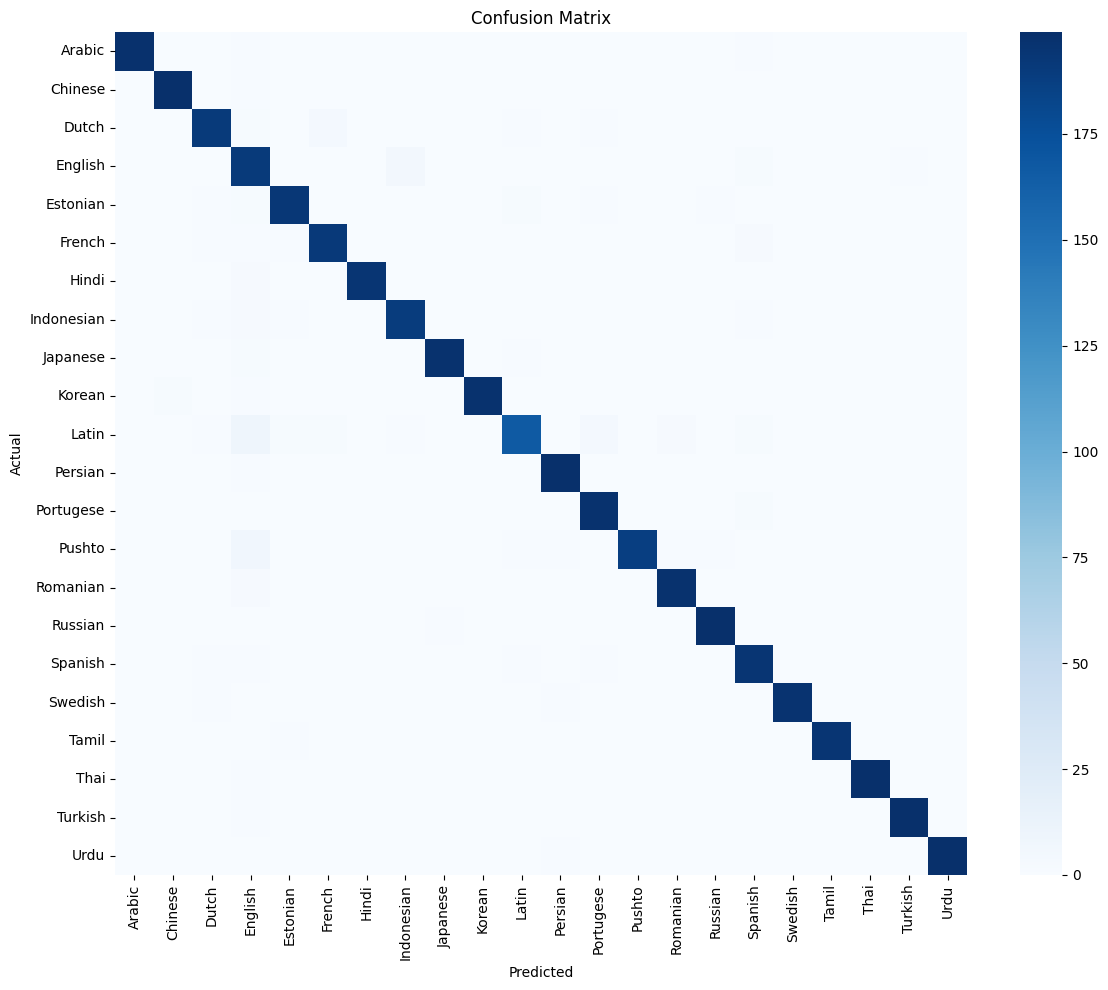


Predictions on unseen samples:
The weather is very nice today and we are going to the park.
  -> English (97.87%)

Je voudrais réserver une table pour deux personnes ce soir.
  -> French (99.82%)

Me gusta mucho aprender cosas nuevas todos los días.
  -> Spanish (79.52%)

நான் இன்று கல்லூரிக்கு செல்கிறேன்
  -> Tamil (100.00%)

मैं आज कॉलेज जा रहा हूँ
  -> Hindi (100.00%)



In [9]:
matrix = confusion_matrix(y_test, y_predicted)
plt.figure(figsize=(12, 10))
sns.heatmap(matrix, annot=number_of_classes <= 15, fmt="d", cmap="Blues",
            xticklabels=label_encoder.classes_, yticklabels=label_encoder.classes_)
plt.xlabel("Predicted")
plt.ylabel("Actual")
plt.title("Confusion Matrix")
plt.tight_layout()
plt.show()


def predict_language(sentence):
    padded = to_padded([clean_text(sentence)])
    probabilities = model.predict(padded, verbose=0)[0]
    top_indices = np.argsort(probabilities)[::-1][:3]
    return [(label_encoder.classes_[index], float(probabilities[index])) for index in top_indices]


unseen_samples = [
    "The weather is very nice today and we are going to the park.",
    "Je voudrais réserver une table pour deux personnes ce soir.",
    "Me gusta mucho aprender cosas nuevas todos los días.",
    "நான் இன்று கல்லூரிக்கு செல்கிறேன்",
    "मैं आज कॉलेज जा रहा हूँ",
]

print("\nPredictions on unseen samples:")
for sample in unseen_samples:
    best_language, best_confidence = predict_language(sample)[0]
    print(f"{sample}\n  -> {best_language} ({best_confidence:.2%})\n")


In [10]:
print("Supported languages:", list(label_encoder.classes_))
while True:
    user_text = input("Type a sentence (type 'exit' to stop): ")
    if user_text.lower() == "exit":
        break
    results = predict_language(user_text)
    print("Predicted language:", results[0][0])
    for language, confidence in results:
        print(f"   {language}: {confidence:.2%}")
    if results[0][1] < 0.6:
        print("   (Low confidence: this language may not be in the dataset, or the sentence is too short)")
    print()


Supported languages: ['Arabic', 'Chinese', 'Dutch', 'English', 'Estonian', 'French', 'Hindi', 'Indonesian', 'Japanese', 'Korean', 'Latin', 'Persian', 'Portugese', 'Pushto', 'Romanian', 'Russian', 'Spanish', 'Swedish', 'Tamil', 'Thai', 'Turkish', 'Urdu']
Type a sentence (type 'exit' to stop): 我今天要去学校和朋友一起学习
Predicted language: Chinese
   Chinese: 100.00%
   Tamil: 0.00%
   Korean: 0.00%

Type a sentence (type 'exit' to stop): 저는 오늘 친구들과 함께 학교에 가서 공부합니다
Predicted language: Korean
   Korean: 100.00%
   Chinese: 0.00%
   Thai: 0.00%

Type a sentence (type 'exit' to stop): ذهبت أمس إلى المدرسة مع أصدقائي وتعلمنا دروسا جديدة
Predicted language: Arabic
   Arabic: 99.99%
   Pushto: 0.01%
   Persian: 0.00%

Type a sentence (type 'exit' to stop): วันนี้ฉันไปโรงเรียนกับเพื่อนและเรียนหนังสือด้วยกัน
Predicted language: Thai
   Thai: 100.00%
   Pushto: 0.00%
   Hindi: 0.00%

Type a sentence (type 'exit' to stop): Gallia est omnis divisa in partes tres, quarum unam incolunt Belgae
Predicted language: